# 10. Импутация пропусков

Рабочий ноутбук к главе книги `../chapters/10-imputation.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 15 пособия.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/10-имя.png`.

In [1]:
import os
import warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from etna.datasets import TSDataset
from etna.transforms import TimeSeriesImputerTransform
from etna.analysis import plot_imputation

IMG_DIR = "../chapters/img"  # графики для главы книги
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/10-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/10-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Синтетика: стратегии заполнения

Ряд с недельной сезонностью, где мы знаем правильные значения на месте пропусков.

### Шаг 1.1. Ряд с пропусками

Синтетический ряд с недельной сезонностью; убери 8 одиночных дней и блок из 10 дней подряд (длиннее недели), сохрани правильные значения.

дней: 112, пропусков: 18 (одиночных: 8, в блоке: 10)


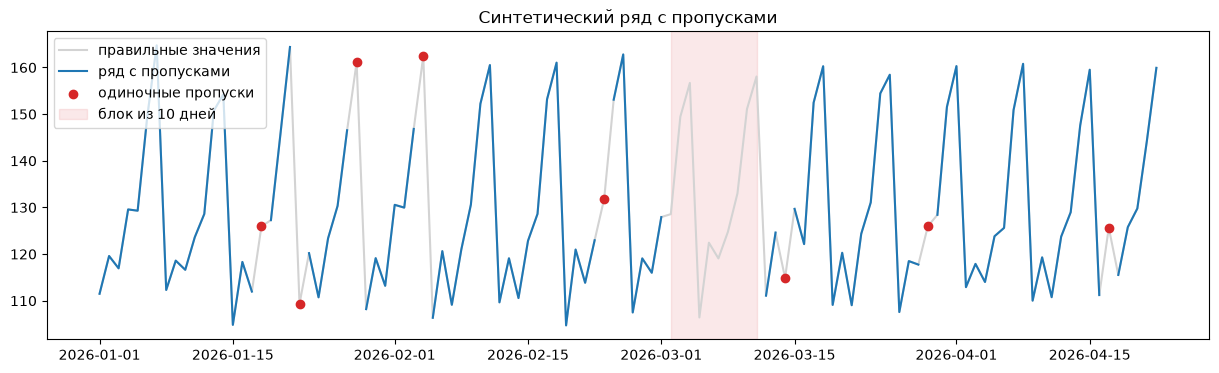

In [2]:
# Ряд: уровень 100 + недельный узор + шум, 16 недель. Правильные значения сохраняем — с ними будем сверять заполнение
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)
PERIODS = 16 * 7

rng = np.random.RandomState(RANDOM_SEED)
timestamps = pd.date_range("2026-01-01", periods=PERIODS, freq="D")
true_values = pd.Series(
    100 + np.tile(DAY_OF_WEEK_PATTERN, PERIODS // 7) + rng.normal(0, 3, PERIODS),
    index=timestamps,
)

# Пропуски двух видов: 8 одиночных дней и один блок из 10 дней подряд (длиннее недели).
# Первые две недели не трогаем: стратегиям, которые смотрят в прошлое, нужна история
block_days = list(range(60, 70))
single_days = sorted(rng.choice([d for d in range(14, PERIODS) if d not in range(58, 72)], size=8, replace=False))
gap_kind = pd.Series("", index=timestamps)
gap_kind.iloc[single_days] = "single"
gap_kind.iloc[block_days] = "block"

observed = true_values.copy()
observed[gap_kind != ""] = np.nan
ts = TSDataset(pd.DataFrame({"timestamp": timestamps, "segment": "synthetic", "target": observed.values}), freq="D")

print(f"дней: {PERIODS}, пропусков: {observed.isna().sum()} (одиночных: {len(single_days)}, в блоке: {len(block_days)})")

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(true_values.index, true_values.values, color="lightgrey", label="правильные значения")
ax.plot(observed.index, observed.values, color="C0", label="ряд с пропусками")
ax.scatter(true_values[gap_kind == "single"].index, true_values[gap_kind == "single"], color="C3", zorder=3, label="одиночные пропуски")
ax.axvspan(timestamps[block_days[0]], timestamps[block_days[-1]], color="C3", alpha=0.1, label="блок из 10 дней")
ax.legend(loc="upper left")
ax.set_title("Синтетический ряд с пропусками")
save_fig(fig, "gaps")

#### Выводы

- Ряд — 16 недель (112 дней): уровень 100, недельный узор размахом 50 заказов и шум ±3. Правильные значения сохранены, с ними сверяем заполнение.
- Пропусков 18 двух видов: **8 одиночных дней** и **блок из 10 дней подряд**. Блок специально длиннее недели — так видно, как стратегии справляются, когда пропал целый «тот же день неделю назад».
- Первые две недели без пропусков: стратегиям, которые смотрят в прошлое, нужна история. Пропуск в самом начале ряда им заполнить нечем — он остаётся пустым (на этот случай у `TimeSeriesImputerTransform` есть `default_value`).

### Шаг 1.2. Все стратегии

Заполни пропуски всеми стратегиями `TimeSeriesImputerTransform`: `constant`, `mean`, `forward_fill`, `running_mean`, `seasonal`, `seasonal_nonautoreg`; посмотри, как каждая заполнила блок.

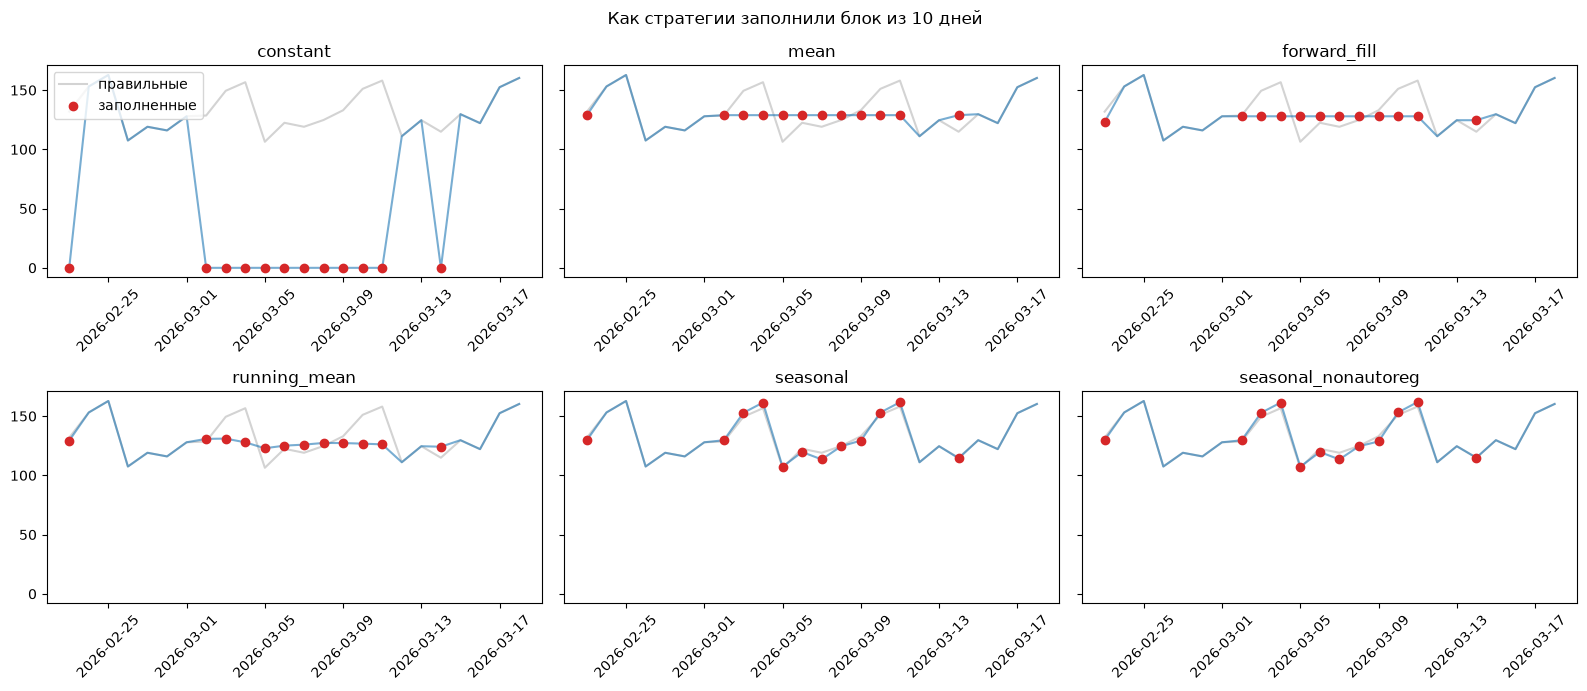

In [3]:
# Все стратегии. running_mean и seasonal — одно и то же «среднее прошлых значений», отличаются шагом:
# running_mean берёт соседние дни (seasonality=1), seasonal — тот же день недели (seasonality=7)
STRATEGIES = {
    "constant": dict(strategy="constant", constant_value=0),
    "mean": dict(strategy="mean"),
    "forward_fill": dict(strategy="forward_fill"),
    "running_mean": dict(strategy="running_mean", window=7),
    "seasonal": dict(strategy="seasonal", seasonality=7, window=3),
    "seasonal_nonautoreg": dict(strategy="seasonal_nonautoreg", seasonality=7, window=3),
}

filled = {}  # стратегия → ряд после заполнения
for name, params in STRATEGIES.items():
    ts_filled = deepcopy(ts)
    ts_filled.fit_transform([TimeSeriesImputerTransform(in_column="target", **params)])
    filled[name] = ts_filled[:, "synthetic", "target"]

# Как каждая стратегия заполнила окрестность блока из 10 дней
window_slice = slice(timestamps[block_days[0] - 7], timestamps[block_days[-1] + 7])
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)
for ax, (name, series) in zip(axes.flat, filled.items()):
    ax.plot(true_values[window_slice].index, true_values[window_slice].values, color="lightgrey", label="правильные")
    ax.plot(series[window_slice].index, series[window_slice].values, color="C0", alpha=0.6)
    gaps = gap_kind[window_slice] != ""
    ax.scatter(series[window_slice][gaps].index, series[window_slice][gaps].values, color="C3", zorder=3, label="заполненные")
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=45)
axes.flat[0].legend(loc="upper left")
fig.suptitle("Как стратегии заполнили блок из 10 дней")
fig.tight_layout()
save_fig(fig, "strategies")

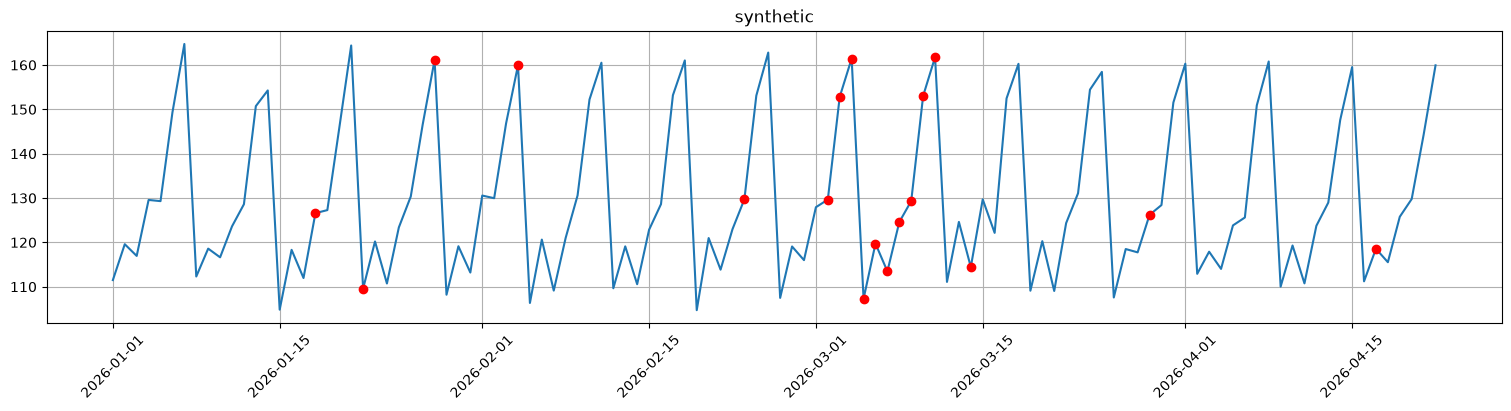

In [4]:
# Тот же результат штатной функцией ETNA — для одной стратегии
seasonal_imputer = TimeSeriesImputerTransform(in_column="target", strategy="seasonal", seasonality=7, window=3)
plot_imputation(ts=deepcopy(ts), imputer=seasonal_imputer, figsize=(15, 4))

#### Выводы

На графике видно три разных поведения:

| стратегия | чем заполняет | что получилось |
|---|---|---|
| `constant` | одним числом (здесь 0) | провалы до нуля — так можно только если «нет данных» действительно значит «ноль» |
| `mean`, `forward_fill`, `running_mean` | средним за всю историю / последним значением / средним за 7 соседних дней | ровная линия: недельный узор пропал |
| `seasonal`, `seasonal_nonautoreg` | средним того же дня недели за прошлые недели | недельная форма сохранилась, точки почти легли на правильную линию |

- **`running_mean` и `seasonal` — один и тот же алгоритм:** «среднее прошлых значений». Разница только в шаге: `running_mean` берёт соседние дни, `seasonal` — тот же день недели (`seasonality=7`). Поэтому на ряде с недельной сезонностью первая усредняет пики и провалы, а вторая — нет.
- **`seasonal` против `seasonal_nonautoreg`:** первая для следующих пропусков использует уже заполненные значения, вторая — только настоящие. На блоке из 10 дней разницы почти не видно: «неделю назад» пропало только для последних трёх дней блока, а окно `window=3` берёт ещё две недели раньше.

### Шаг 1.3. Ошибка заполнения

Средняя ошибка заполненных значений против правильных — отдельно для одиночных пропусков и для блока.

In [5]:
# Ошибка заполнения: насколько заполненные значения отличаются от правильных — отдельно для одиночных и для блока
error_rows = []
for name, series in filled.items():
    abs_error = (series - true_values).abs()
    error_rows.append({
        "strategy": name,
        "mae_single": abs_error[gap_kind == "single"].mean(),
        "mae_block": abs_error[gap_kind == "block"].mean(),
        "left_nan": int(series[gap_kind != ""].isna().sum()),  # пропуски, которые стратегия не смогла заполнить
    })

errors_df = pd.DataFrame(error_rows).set_index("strategy").sort_values("mae_block")
print("размах недельного узора:", DAY_OF_WEEK_PATTERN.max() - DAY_OF_WEEK_PATTERN.min(), "| шум: sd = 3")
errors_df.round(1)

размах недельного узора: 50.0 | шум: sd = 3


,mae_single,mae_block,left_nan
strategy,,,
seasonal,1.7,2.8,0
seasonal_nonautoreg,1.8,2.9,0
running_mean,13.2,14.0,0
mean,13.9,14.7,0
forward_fill,17.6,14.8,0
constant,132.2,135.0,0


#### Выводы

| стратегия | ошибка на одиночных пропусках | ошибка на блоке из 10 дней |
|---|---|---|
| `seasonal` | **1.7** | **2.8** |
| `seasonal_nonautoreg` | 1.8 | 2.9 |
| `running_mean` | 13.2 | 14.0 |
| `mean` | 13.9 | 14.7 |
| `forward_fill` | 17.6 | 14.8 |
| `constant` (0) | 132.2 | 135.0 |

*Ошибка — среднее отклонение заполненного значения от правильного, в заказах.*

- **Сезонные стратегии почти идеальны:** ошибка 2–3 заказа — на уровне самого шума в ряде (±3). Лучше заполнить нельзя: шум отдельного дня не предсказать.
- **Несезонные стратегии ошибаются на 13–18 заказов** — примерно на четверть размаха недельного узора. Они ставят «средний день» туда, где был пик или провал.
- **Блок заполняется чуть хуже одиночных пропусков** (2.8 против 1.7 у `seasonal`): для последних дней блока «тот же день неделю назад» тоже пропал, и опора — на более старые недели или на уже заполненные значения.
- **`constant` = 0 — худший вариант для заказов:** ошибка равна уровню ряда. Ноль уместен, только когда пропуск действительно означает «ничего не было» (юнит закрыт).

**Итог:** если в ряде есть сезонность, заполнять пропуски нужно сезонной стратегией с `seasonality`, равной периоду (для дневных данных с недельным узором — 7). Остальные стратегии стирают узор, и модель потом учится на искажённом ряде.